In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
df = pd.read_csv("train.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (1460, 81)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [4]:
print("Dataset Information:")
df.info()

print("\nDataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDescriptive Statistics:")
display(df.describe())

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   str    
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   str    
 6   Alley          91 non-null     str    
 7   LotShape       1460 non-null   str    
 8   LandContour    1460 non-null   str    
 9   Utilities      1460 non-null   str    
 10  LotConfig      1460 non-null   str    
 11  LandSlope      1460 non-null   str    
 12  Neighborhood   1460 non-null   str    
 13  Condition1     1460 non-null   str    
 14  Condition2     1460 non-null   str    
 15  BldgType       1460 non-null   str    
 16  HouseStyle     1460 non-null   str    
 17  OverallQual    1460 non-null   int64  
 18

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


In [5]:
# Check missing values in each column
missing_values = df.isnull().sum()

# Display columns having missing values
missing_values = missing_values[missing_values > 0].sort_values(ascending=False)

print("Columns with missing values:")
display(missing_values)

Columns with missing values:


PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
GarageCond        81
BsmtFinType2      38
BsmtExposure      38
BsmtFinType1      37
BsmtCond          37
BsmtQual          37
MasVnrArea         8
Electrical         1
dtype: int64

In [6]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


In [7]:
print("Sale Price Statistics:")
display(df["SalePrice"].describe())

print("Average House Price:", df["SalePrice"].mean())
print("Minimum House Price:", df["SalePrice"].min())
print("Maximum House Price:", df["SalePrice"].max())

Sale Price Statistics:


count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64

Average House Price: 180921.19589041095
Minimum House Price: 34900
Maximum House Price: 755000


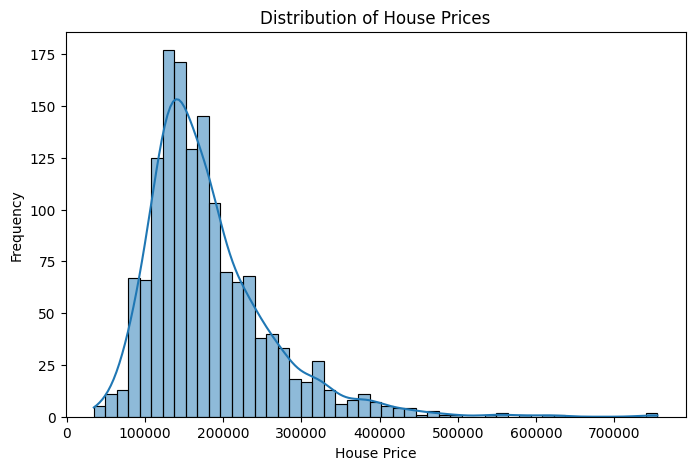

In [8]:
plt.figure(figsize=(8, 5))

sns.histplot(df["SalePrice"], kde=True)

plt.title("Distribution of House Prices")
plt.xlabel("House Price")
plt.ylabel("Frequency")

plt.show()

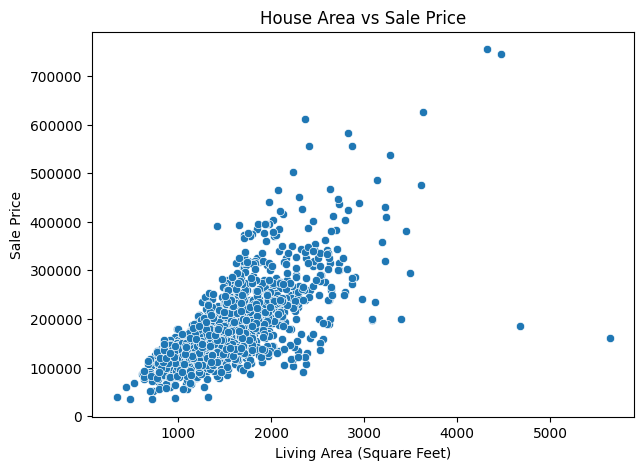

In [9]:
plt.figure(figsize=(7, 5))

sns.scatterplot(data=df, x="GrLivArea", y="SalePrice")

plt.title("House Area vs Sale Price")
plt.xlabel("Living Area (Square Feet)")
plt.ylabel("Sale Price")

plt.show()

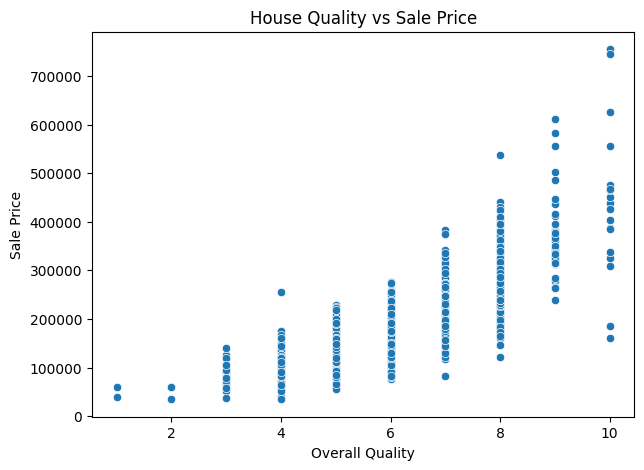

In [10]:
plt.figure(figsize=(7, 5))

sns.scatterplot(data=df, x="OverallQual", y="SalePrice")

plt.title("House Quality vs Sale Price")
plt.xlabel("Overall Quality")
plt.ylabel("Sale Price")

plt.show()

### Feature Selection

Feature selection is the process of choosing important columns
that help predict house prices.

The following features are selected:

1. GrLivArea – Total living area of the house.
2. OverallQual – Overall quality of the house.
3. GarageCars – Number of cars that can fit in the garage.
4. TotalBsmtSF – Total basement area.
5. YearBuilt – Year in which the house was built.
6. Neighborhood – Location of the house.
7. BedroomAbvGr – Number of bedrooms.
8. FullBath – Number of full bathrooms.

SalePrice is selected as the target variable because it is
the price we want to predict.

In [12]:
# Select important features
features = [
    "GrLivArea",
    "OverallQual",
    "GarageCars",
    "TotalBsmtSF",
    "YearBuilt",
    "Neighborhood",
    "BedroomAbvGr",
    "FullBath"
]

X = df[features]
y = df["SalePrice"]

print("Input features shape:", X.shape)
print("Target variable shape:", y.shape)

display(X.head())

Input features shape: (1460, 8)
Target variable shape: (1460,)


,GrLivArea,OverallQual,GarageCars,TotalBsmtSF,YearBuilt,Neighborhood,BedroomAbvGr,FullBath
0,1710,7,2,856,2003,CollgCr,3,2
1,1262,6,2,1262,1976,Veenker,3,2
2,1786,7,2,920,2001,CollgCr,3,2
3,1717,7,3,756,1915,Crawfor,3,1
4,2198,8,3,1145,2000,NoRidge,4,2


In [14]:
# Identify numerical and categorical columns
numerical_features = X.select_dtypes(include=["number"]).columns.tolist()

categorical_features = X.select_dtypes(include=["str", "object"]).columns.tolist()

print("Numerical Features:")
print(numerical_features)

print("\nCategorical Features:")
print(categorical_features)

Numerical Features:
['GrLivArea', 'OverallQual', 'GarageCars', 'TotalBsmtSF', 'YearBuilt', 'BedroomAbvGr', 'FullBath']

Categorical Features:
['Neighborhood']


In [15]:
# Handle missing numerical values using median
numerical_transformer = SimpleImputer(strategy="median")

# Handle missing categorical values using most frequent value
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing steps
preprocessor = ColumnTransformer(transformers=[
    ("num", numerical_transformer, numerical_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Data preprocessing setup completed!")

Data preprocessing setup completed!


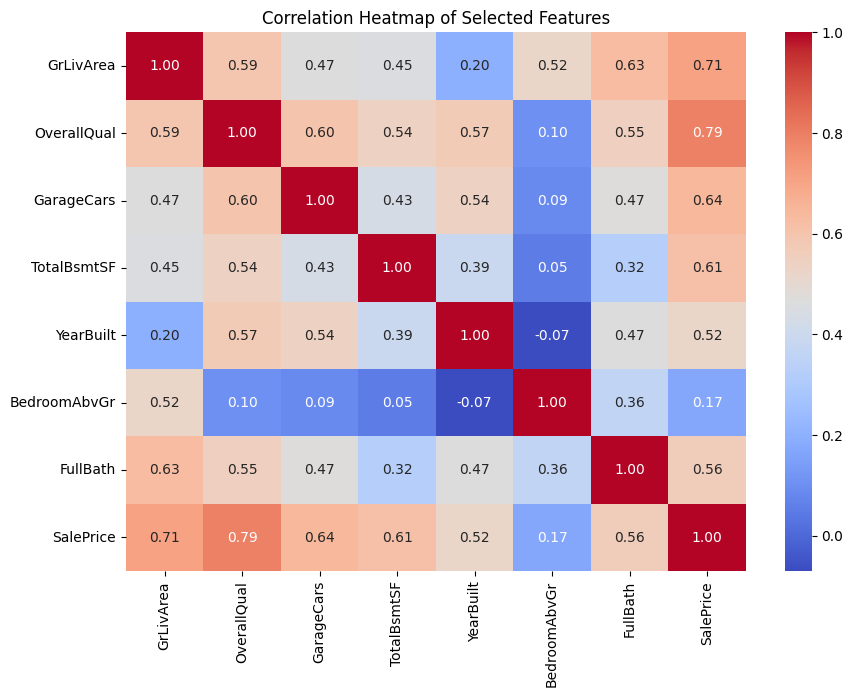

In [16]:
plt.figure(figsize=(10, 7))

correlation = df[features + ["SalePrice"]].select_dtypes(include=["number"]).corr()

sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f")

plt.title("Correlation Heatmap of Selected Features")
plt.show()

In [17]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (1168, 8)
Testing data: (292, 8)


In [18]:
# Create Linear Regression pipeline
linear_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

print("Linear Regression model created successfully!")

Linear Regression model created successfully!


In [19]:
# Train the model using training data
linear_model.fit(X_train, y_train)

print("Model training completed successfully!")

Model training completed successfully!


In [20]:
# Predict prices using test data
y_pred = linear_model.predict(X_test)

print("House price predictions completed!")

# Display actual and predicted prices
comparison = pd.DataFrame({
    "Actual Price": y_test.values,
    "Predicted Price": y_pred
})

display(comparison.head(10))

House price predictions completed!


,Actual Price,Predicted Price
0,154500,140465.643867
1,325000,328676.326483
2,115000,114386.938480
3,159000,180161.161700
4,315500,284841.464513
5,75500,61618.858057
6,311500,228871.345215
7,146000,152638.758381
8,84500,61096.820752
9,135500,124284.268771


In [21]:
# Calculate evaluation metrics
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Model Evaluation Results")
print("------------------------")
print("Mean Squared Error (MSE):", round(mse, 2))
print("Root Mean Squared Error (RMSE):", round(rmse, 2))
print("R2 Score:", round(r2, 4))

Model Evaluation Results
------------------------
Mean Squared Error (MSE): 1302052783.7
Root Mean Squared Error (RMSE): 36083.97
R2 Score: 0.8302


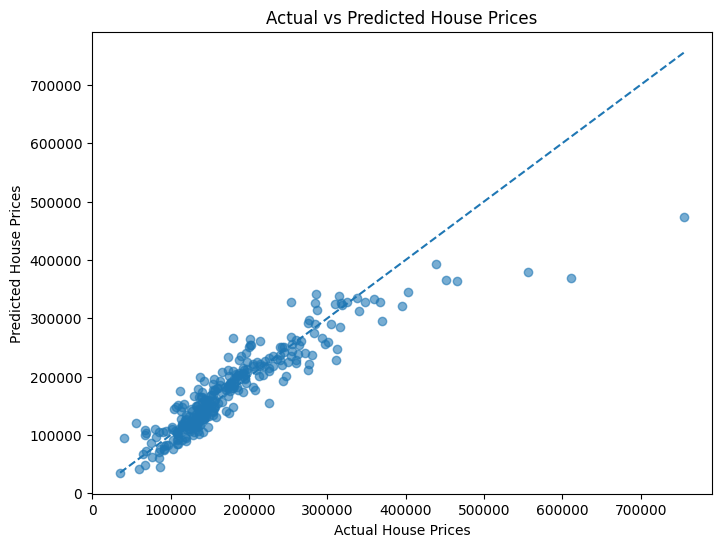

In [22]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.6)

plt.xlabel("Actual House Prices")
plt.ylabel("Predicted House Prices")
plt.title("Actual vs Predicted House Prices")

# Draw reference line
min_price = min(y_test.min(), y_pred.min())
max_price = max(y_test.max(), y_pred.max())

plt.plot([min_price, max_price], [min_price, max_price], linestyle="--")

plt.show()

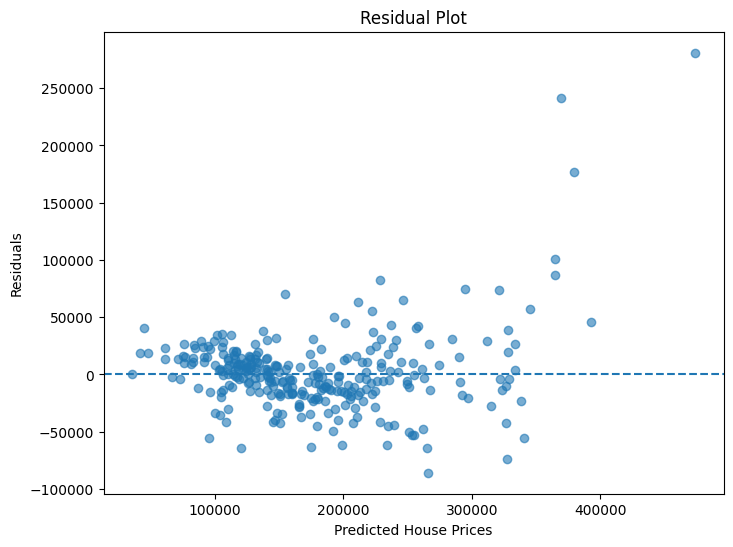

In [23]:
# Calculate residuals
residuals = y_test - y_pred

plt.figure(figsize=(8, 6))

plt.scatter(y_pred, residuals, alpha=0.6)
plt.axhline(y=0, linestyle="--")

plt.xlabel("Predicted House Prices")
plt.ylabel("Residuals")
plt.title("Residual Plot")

plt.show()

In [24]:
# Get feature names after preprocessing
feature_names = linear_model.named_steps["preprocessor"].get_feature_names_out()

# Get model coefficients
coefficients = linear_model.named_steps["model"].coef_

# Create coefficient dataframe
coef_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

# Sort by absolute coefficient values
coef_df["Absolute Coefficient"] = coef_df["Coefficient"].abs()
coef_df = coef_df.sort_values(
    by="Absolute Coefficient",
    ascending=False
)

display(coef_df.head(15))

,Feature,Coefficient,Absolute Coefficient
29,cat__Neighborhood_StoneBr,46847.393197,46847.393197
23,cat__Neighborhood_NridgHt,46048.840574,46048.840574
22,cat__Neighborhood_NoRidge,44235.001641,44235.001641
9,cat__Neighborhood_BrDale,-40495.260588,40495.260588
31,cat__Neighborhood_Veenker,36424.759057,36424.759057
7,cat__Neighborhood_Blmngtn,-27134.595392,27134.595392
20,cat__Neighborhood_NPkVill,-24126.223701,24126.223701
11,cat__Neighborhood_ClearCr,24046.353428,24046.353428
13,cat__Neighborhood_Crawfor,21129.704080,21129.704080
17,cat__Neighborhood_MeadowV,-20368.137338,20368.137338


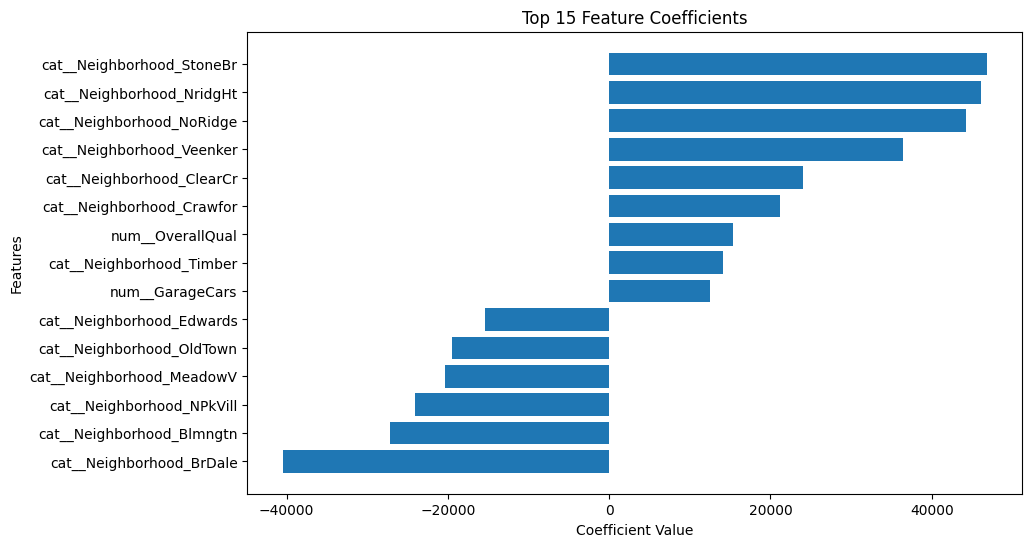

In [25]:
plt.figure(figsize=(10, 6))

top_features = coef_df.head(15).sort_values("Coefficient")

plt.barh(top_features["Feature"], top_features["Coefficient"])

plt.xlabel("Coefficient Value")
plt.ylabel("Features")
plt.title("Top 15 Feature Coefficients")

plt.show()

In [26]:
# Create Ridge Regression pipeline
ridge_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", Ridge(alpha=1.0))
])

# Train Ridge model
ridge_model.fit(X_train, y_train)

# Make predictions
ridge_pred = ridge_model.predict(X_test)

# Evaluate Ridge model
ridge_mse = mean_squared_error(y_test, ridge_pred)
ridge_rmse = np.sqrt(ridge_mse)
ridge_r2 = r2_score(y_test, ridge_pred)

print("Ridge Regression Results")
print("------------------------")
print("MSE:", round(ridge_mse, 2))
print("RMSE:", round(ridge_rmse, 2))
print("R2 Score:", round(ridge_r2, 4))

Ridge Regression Results
------------------------
MSE: 1501558456.19
RMSE: 38749.95
R2 Score: 0.8042


In [27]:
model_comparison = pd.DataFrame({
    "Model": ["Linear Regression", "Ridge Regression"],
    "MSE": [mse, ridge_mse],
    "RMSE": [rmse, ridge_rmse],
    "R2 Score": [r2, ridge_r2]
})

display(model_comparison)

,Model,MSE,RMSE,R2 Score
0,Linear Regression,1.302053e+09,36083.968514,0.830248
1,Ridge Regression,1.501558e+09,38749.947822,0.804238


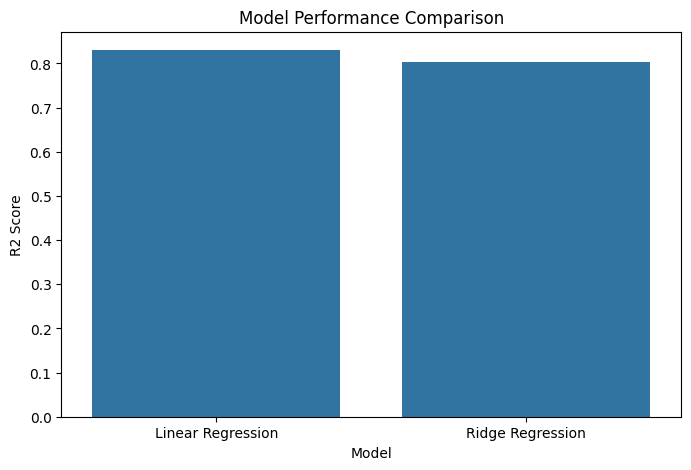

In [28]:
plt.figure(figsize=(8, 5))

sns.barplot(data=model_comparison, x="Model", y="R2 Score")

plt.title("Model Performance Comparison")
plt.ylabel("R2 Score")

plt.show()

In [30]:
import os

# Create Outputs folder in Jupyter's current directory
os.makedirs("Outputs", exist_ok=True)

print("Current working directory:", os.getcwd())
print("Outputs folder created:", os.path.exists("Outputs"))

Current working directory: C:\Users\sanaa\OneDrive\Desktop\OIBSIP\DataAnalytics-Level2-Task1-HousePricePrediction
Outputs folder created: True


In [31]:
comparison.to_csv("Outputs/house_price_predictions.csv", index=False)

model_comparison.to_csv("Outputs/model_comparison.csv", index=False)

coef_df.to_csv("Outputs/model_coefficients.csv", index=False)

print("All results saved successfully!")

All results saved successfully!


## Conclusion

In this project, a House Price Prediction model was developed using Linear Regression.

- The Ames Housing dataset was used for analysis.
- Missing values were handled using imputation techniques.
- Categorical data was converted using One-Hot Encoding.
- Important features were selected for prediction.
- The dataset was divided into 80% training and 20% testing data.
- Linear Regression was trained to predict house prices.
- Model performance was evaluated using MSE, RMSE and R2 Score.
- Actual vs Predicted and Residual plots were created.
- Ridge Regression was also implemented for comparison.

The project demonstrates how machine learning can be used to predict house prices based on property features.